# 🔗 Notebook 2 — Chain Growth & Molecular Weight Distributions
| | |
|---|---|
| ⏱ Time | ~25 min |
| 🎯 You will learn | simulate chains one-by-one · build an MWD · Mn, Mw, Đ · combination vs transfer |
| 🧰 Uses | Trick #1 (`Rnd ≤ P`) and Trick #2 (count) from Notebook 1 |
| 📖 Book algorithms | *Monte Carlo Simulation of MWD* · *Styrene Polymerization Process* · *Improved … with Correct Chain Termination* |

The book (*Monte Carlo Methods in Polymer Reaction Engineering: From Mechanisms to Molecular Architecture*) explains where the probabilities come from (rate constants → `P_p`). Here we just **run** the algorithms and **look** at the results.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
random.seed(1)
plt.rcParams.update({"figure.figsize": (6, 3.6), "axes.grid": True, "grid.alpha": 0.3})
trapz = getattr(np, "trapezoid", None) or np.trapz   # works on old and new NumPy

## 1 · One chain at a time
A living chain keeps asking: *propagate (prob. `P_p`) or stop?* — Trick #1 inside a `while` loop.

```
n ← 1
while Rnd ≤ P_p:  n ← n + 1
record chain of length n
```

In [2]:
def grow_chain(Pp):
    n = 1
    while random.random() <= Pp:
        n += 1
    return n

print("Five chains:", [grow_chain(0.99) for _ in range(5)])

Five chains: [41, 620, 143, 49, 40]


## 2 · Many chains → the chain length distribution (CLD)
We store results in a counting vector `D`: `D[n]` = number of dead chains with length `n`.

Chain-length averages:  Nn = 100.1   Nw = 199.8   Đ = 1.996
Theory (Flory):          Nn = 100.0   Nw = 199.0   Đ = 1.990


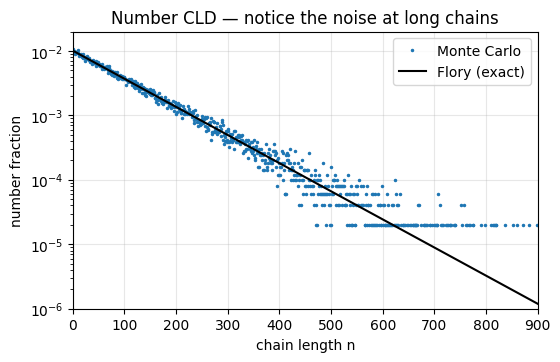

In [3]:
def simulate_chains(N, Pp):
    counts = {}
    for _ in range(N):
        n = grow_chain(Pp)
        counts[n] = counts.get(n, 0) + 1
    D = np.zeros(max(counts) + 1)
    for length, c in counts.items():
        D[length] = c
    return D

def averages(D):
    n = np.arange(len(D))
    Mn = (n*D).sum() / D.sum()
    Mw = (n**2*D).sum() / (n*D).sum()
    return Mn, Mw, Mw/Mn

N, Pp = 50_000, 0.99
D = simulate_chains(N, Pp)
Mn, Mw, PDI = averages(D)
print(f"Chain-length averages:  Nn = {Mn:.1f}   Nw = {Mw:.1f}   Đ = {PDI:.3f}")
print(f"Theory (Flory):          Nn = {1/(1-Pp):.1f}   Nw = {(1+Pp)/(1-Pp):.1f}   Đ = {1+Pp:.3f}")

nn = np.arange(1, len(D))
plt.plot(nn, D[1:]/D.sum(), ".", ms=3, label="Monte Carlo")
plt.plot(nn, (1-Pp)*Pp**(nn-1), "k-", label="Flory (exact)")
plt.yscale("log"); plt.xlim(0, 900); plt.ylim(1e-6, 2e-2); plt.xlabel("chain length n"); plt.ylabel("number fraction")
plt.title("Number CLD — notice the noise at long chains"); plt.legend(); plt.show()

## 3 · From raw counts to a *smooth*, log-scale MWD
Raw counts are noisy at long chains. The book's post-processing recipe:
1. **Group** lengths into bins of width `Δn`
2. **Normalize** (area = 1, trapezoidal rule)
3. Convert **number → weight** distribution (`w = n·f`)
4. Convert to the **log scale** used by GPC/SEC (`w_log = ln(10)·MW·w`)

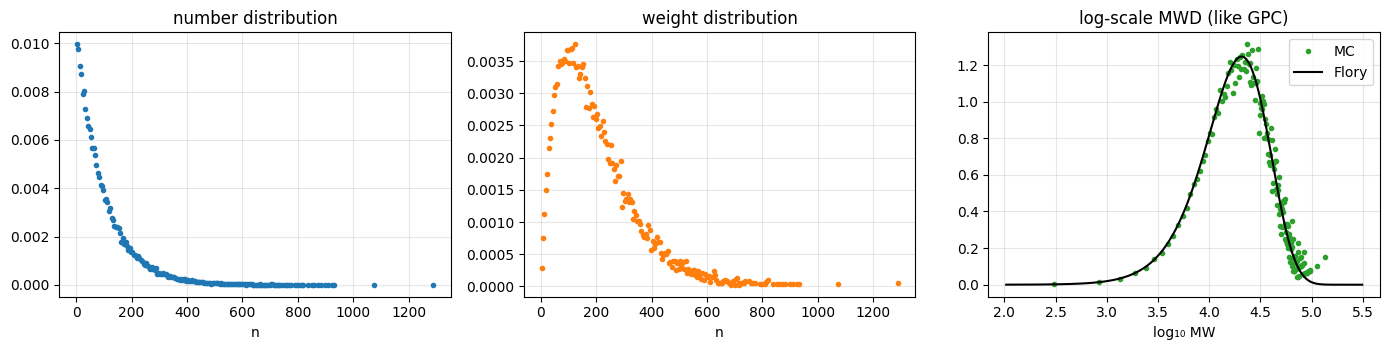

In [4]:
def log_mwd(D, MW_mer=104.15, dn=5):
    """Grouped, normalized number / weight / log-scale MWDs from a counting vector D."""
    n = np.arange(len(D))
    x, y = [], []
    for start in range(1, len(D), dn):                 # Step 2: group into bins
        sel = slice(start, start + dn)
        if D[sel].sum() > 0:
            x.append((n[sel]*D[sel]).sum() / D[sel].sum())
            y.append(D[sel].sum())
    x, y = np.array(x), np.array(y)
    f = y / trapz(y, x)                                  # Step 3: number distribution
    w = x * f;  w /= trapz(w, x)                         # Step 4: weight distribution
    MW = x * MW_mer
    wlog = np.log(10) * MW * w                           # Step 5: log scale
    wlog /= trapz(wlog, np.log10(MW))
    return x, f, w, np.log10(MW), wlog

x, f, w, logMW, wlog = log_mwd(D, dn=5)

# exact Flory curve for comparison
nf = np.arange(1, 3000); wf = nf*(1-Pp)**2*Pp**(nf-1)
wlog_f = np.log(10)*nf*wf; wlog_f /= trapz(wlog_f, np.log10(nf*104.15))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(x, f, "o", ms=3); ax[0].set_title("number distribution"); ax[0].set_xlabel("n")
ax[1].plot(x, w, "o", ms=3, c="tab:orange"); ax[1].set_title("weight distribution"); ax[1].set_xlabel("n")
ax[2].plot(logMW, wlog, "o", ms=3, c="tab:green", label="MC")
ax[2].plot(np.log10(nf*104.15), wlog_f, "k-", label="Flory")
ax[2].set_title("log-scale MWD (like GPC)"); ax[2].set_xlabel("log₁₀ MW"); ax[2].legend()
plt.tight_layout(); plt.show()

### 💡 Second option: logarithmic bins
Equal-width bins (`Δn`) get sparse and noisy on a log axis at high MW. Bins that are equally spaced in **log n** fix that. We'll use this helper from now on.

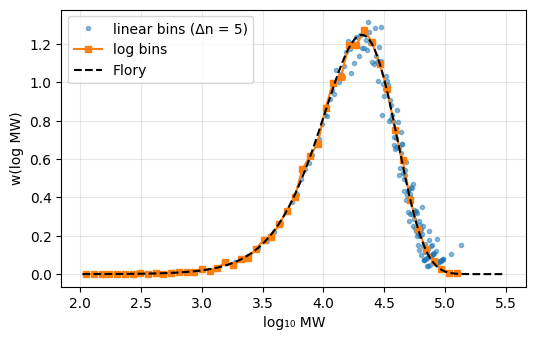

In [5]:
def log_binned_mwd(D, MW_mer=104.15, bins=50):
    n = np.arange(len(D))
    edges = np.logspace(0, np.log10(len(D)), bins)
    mass, _ = np.histogram(n, bins=edges, weights=n*D)      # mass of chains in each bin
    x = np.log10(np.sqrt(edges[1:]*edges[:-1]) * MW_mer)
    y = mass / np.diff(np.log10(edges))
    return x, y / trapz(y, x)

xl, yl = log_binned_mwd(D)
plt.plot(logMW, wlog, "o", ms=3, alpha=0.5, label="linear bins (Δn = 5)")
plt.plot(xl, yl, "s-", ms=4, label="log bins")
plt.plot(np.log10(nf*104.15), wlog_f, "k--", label="Flory")
plt.xlabel("log₁₀ MW"); plt.ylabel("w(log MW)"); plt.legend(); plt.show()

## 4 · How many chains do I need?
Trick #2 again: the noise falls like 1/√N. Try it — small N gives a jagged MWD.

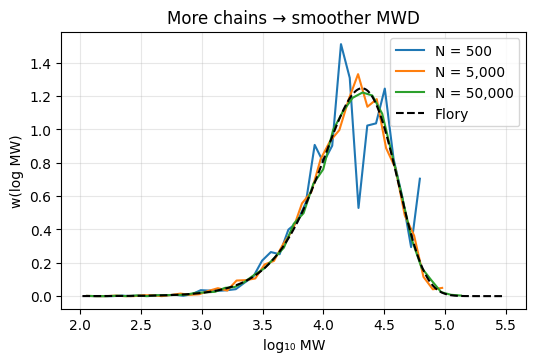

In [6]:
for N_try in [500, 5_000, 50_000]:
    lm, wl = log_binned_mwd(simulate_chains(N_try, Pp), bins=40)
    plt.plot(lm, wl, label=f"N = {N_try:,}")
plt.plot(np.log10(nf*104.15), wlog_f, "k--", label="Flory")
plt.xlabel("log₁₀ MW"); plt.ylabel("w(log MW)"); plt.legend(); plt.title("More chains → smoother MWD"); plt.show()

### 💡 Side note: a faster way
Each chain length here follows a *geometric* distribution, so NumPy can draw all chains at once.
Loops are better for **learning** and for **complex mechanisms**; vectorized tricks are for **speed** when the math is simple.

In [7]:
import time
t0 = time.time(); D_loop = simulate_chains(50_000, Pp); t_loop = time.time() - t0
t0 = time.time(); lengths = np.random.geometric(1 - Pp, size=50_000); t_vec = time.time() - t0
print(f"loop: {t_loop:.3f} s   vectorized: {t_vec:.4f} s")
print(f"Nn loop = {averages(D_loop)[0]:.1f},  Nn vectorized = {lengths.mean():.1f}")

loop: 0.213 s   vectorized: 0.0150 s
Nn loop = 100.1,  Nn vectorized = 100.3


## 5 · Styrene: termination by **combination** vs **transfer**
When a chain stops, two things can happen:
- **transfer to monomer** (prob. `1 − P_tc`): the chain is dead as it is → record `n`
- **combination** (prob. `P_tc`): it couples with a *second* growing chain → record `n + m`

### Version A (simple)
Grow a second chain `m` and combine. But wait — that second chain was itself allowed to stop by *transfer*, not just combination...

In [8]:
def styrene_simple(N, Pp, Ptc):
    out, n_comb = [], 0
    for _ in range(N):
        n = grow_chain(Pp)
        if random.random() <= Ptc:
            m = grow_chain(Pp)
            out.append(n + m); n_comb += 1   # combination
        else:
            out.append(n)                    # transfer to monomer
    return np.array(out), n_comb

### Version B (improved — as in the book)
The second chain must *also* decide how it ends. If it picks **transfer**, it is recorded as its own dead chain and we try again, **repeat until** a partner that truly ends by combination is found.

In [9]:
def generate_second_chain(Pp, Ptc, out):
    while True:
        m = grow_chain(Pp)
        if random.random() <= Ptc:     # partner also terminates by combination
            return m
        out.append(m)                  # partner transferred → it's a dead chain on its own

def styrene_improved(N, Pp, Ptc):
    out, n_comb = [], 0
    for _ in range(N):
        n = grow_chain(Pp)
        if random.random() <= Ptc:
            out.append(n + generate_second_chain(Pp, Ptc, out)); n_comb += 1
        else:
            out.append(n)
    return np.array(out), n_comb

### Does it matter? Compare the fraction of chains formed by combination
For `P_tc = 0.5`, a little bookkeeping (see book) says that **1/3** of dead chains should come from combination.

In [10]:
Pp, Ptc, N = 0.99, 0.5, 20_000
A, combA = styrene_simple(N, Pp, Ptc)
B, combB = styrene_improved(N, Pp, Ptc)

theory = (Ptc/2) / (Ptc/2 + 1 - Ptc)
print(f"Fraction of dead chains from combination:")
print(f"   simple   = {combA/len(A):.3f}")
print(f"   improved = {combB/len(B):.3f}")
print(f"   theory   = {theory:.3f}")

Fraction of dead chains from combination:
   simple   = 0.499
   improved = 0.332
   theory   = 0.333


### The classic result: Đ ≈ 2 for transfer, Đ ≈ 1.5 for pure combination

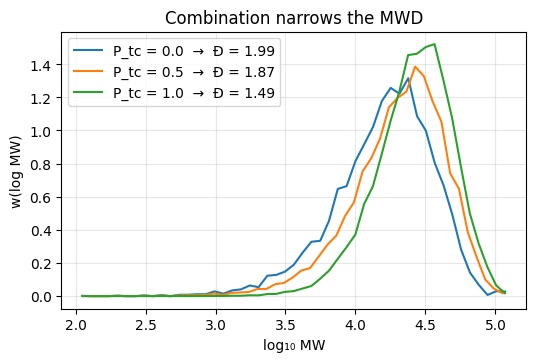

In [11]:
for Ptc in [0.0, 0.5, 1.0]:
    L, _ = styrene_improved(20_000, 0.99, Ptc)
    Dv = np.bincount(L)
    lm, wl = log_binned_mwd(Dv)
    plt.plot(lm, wl, label=f"P_tc = {Ptc}  →  Đ = {averages(Dv)[2]:.2f}")
plt.xlabel("log₁₀ MW"); plt.ylabel("w(log MW)"); plt.legend(); plt.title("Combination narrows the MWD"); plt.show()

## ✅ Recap
- One `while Rnd ≤ P_p` loop = one chain. Repeat → distribution.
- Post-processing (group → normalize → weight → log) turns counts into a GPC-like curve.
- **Small details in the algorithm** (how the partner chain ends) change the answer — always validate against a known result!

### 🧪 Try it yourself
1. Change `P_p` to 0.999. How does Nn change? (Expect 1/(1−P_p).)
2. Change the bin width `dn` in `log_mwd`. When is it too coarse? Too fine?
3. Use `MW_mer = 100.12` (MMA) instead of styrene.

➡️ **Next: Notebook 3 — Copolymers & composition**